# 01 · 电商用户流失预警：口径、泄漏与阈值

这个 Notebook 不复述业务结论，只做三件事：**把口径讲清、把泄漏拆掉、把阈值定对**。

> 面试里最常被追问的三个问题，这里都有可运行的回答：
> 1. 「AUC 0.78 怎么验证的？」→ 时间窗外验证 + 十分位 lift 校验
> 2. 「为什么不用券特征？」→ 加它能到 0.796，但上线不可知，属于泄漏
> 3. 「阈值怎么定的？」→ 按运营承接量倒推，不是 F1 最优点

数据说明：公司宽表不能外带，这里用**同构数据**（`src/gen.py`）验证方法，
它保留了同样的字段结构、同样的泄漏方向，并且知道每个人的真实流失概率。

## 1. 数据与标签口径

一人一行，快照时点 = 观察窗终点。标签 = 标签窗内是否下单。

| 项 | 设定 |
|---|---|
| 观察窗 | 2024-08-01 ~ 2024-09-14（45 天） |
| 标签窗 | 2024-09-15 ~ 2024-10-14（30 天） |
| 用户池 | 观察窗内有活跃（浏览或下单） |
| 正样本 | 标签窗内无支付订单（退款不算下单） |

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.gen import build, save
from src.model import (FEATURES, LEAKY, fit_logreg, predict_proba, auc, ks,
                       at_capacity, f1_optimal_capacity, cost_model)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
print("仓库根目录：", ROOT)

仓库根目录： C:\Users\50521\Desktop\chenism\portfolio\ecom-churn


In [2]:
out = ROOT / "outputs"
if not (out / "user_snapshot.csv").exists():
    df, truth = build()
    save(df, truth, out)
else:
    df = pd.read_csv(out / "user_snapshot.csv")
    truth = json.loads((out / "ground_truth.json").read_text(encoding="utf-8"))

print(f"用户 {len(df):,}｜流失率 {df['churn'].mean():.1%}｜字段 {df.shape[1]} 个")
df.head()

用户 120,000｜流失率 13.4%｜字段 16 个


,user_id,tenure_days,recency_days,freq_30d,orders_90d,gmv_90d,browse_30d,search_30d,cart_30d,tickets_30d,return_rate_90d,cat_diversity,coupon_received_30d,coupon_used_30d,is_new,churn
0,1,77,42,7,18,139.40,25,13,2,0,0.152,1,1,0,1,0
1,2,131,18,5,9,283.23,52,8,4,1,0.025,3,0,0,0,0
2,3,300,17,9,18,266.47,111,24,3,0,0.000,2,1,0,0,0
3,4,102,29,4,13,327.10,61,12,3,0,0.075,1,1,0,0,0
4,5,284,25,8,16,561.98,41,15,3,2,0.072,1,1,1,0,0


**先看分群**：新客与老客的流失率差一倍以上。混在一起算平均，会得到一个谁都不像的数——
这也是后面评估要分群看的原因之一。

In [3]:
(df.assign(用户类型=lambda d: np.where(d.is_new == 1, "新客（<90天）", "老客"))
   .groupby("用户类型")
   .agg(用户数=("user_id", "count"), 流失率=("churn", "mean"),
        平均下单次数=("freq_30d", "mean"), 平均浏览=("browse_30d", "mean"))
   .round(3))

,用户数,流失率,平均下单次数,平均浏览
用户类型,,,,
新客（<90天）,9488,0.223,5.066,45.114
老客,110512,0.126,5.073,45.586


## 2. 特征与泄漏

特征白名单在 `src/model.py` 的 `FEATURES` 里，一共 12 个；`LEAKY` 里单独放了两个券字段，
**只用来做对照实验**。

下面跑两版模型，看泄漏能把 AUC 抬高多少。

In [4]:
rng = np.random.default_rng(0)
idx = rng.permutation(len(df))
cut = int(len(df) * 0.7)
train, test = df.iloc[idx[:cut]], df.iloc[idx[cut:]]

def run(feats, l2=2.0):
    Xtr, Xte = train[feats].to_numpy(float), test[feats].to_numpy(float)
    mu, sd = Xtr.mean(0), Xtr.std(0)
    sd[sd == 0] = 1
    w = fit_logreg((Xtr - mu) / sd, train["churn"].to_numpy(float), l2=l2)
    score = predict_proba((Xte - mu) / sd, w)
    y = test["churn"].to_numpy()
    return score, auc(y, score), ks(y, score), w, mu, sd

score_clean, auc_clean, ks_clean, w, mu, sd = run(FEATURES)
score_leak, auc_leak, ks_leak, _, _, _ = run(FEATURES + LEAKY)

pd.DataFrame({
    "特征集": ["白名单（12 个特征）", "白名单 + 券（泄漏）"],
    "AUC": [auc_clean, auc_leak],
    "KS": [ks_clean, ks_leak],
}).round(3)

,特征集,AUC,KS
0,白名单（12 个特征）,0.774,0.413
1,白名单 + 券（泄漏）,0.810,0.469


对应简历里的两个数：**基线规则 0.69、模型 0.78**。这里是同构数据，量级与业务口径一致（具体值见上表）；
真正要看的不是小数点后三位，而是**加泄漏特征后 AUC 会虚高 0.03 以上**——这个偏移在真实项目里通常更大。

In [5]:
coef = pd.Series(w[1:], index=FEATURES).sort_values(key=abs, ascending=False)
(coef.to_frame("标准化系数")
     .assign(方向=lambda d: np.where(d["标准化系数"] > 0, "流失↑", "流失↓"))
     .round(3))

,标准化系数,方向
recency_days,-0.307,流失↓
freq_30d,0.252,流失↑
browse_30d,0.231,流失↑
is_new,0.222,流失↑
cart_30d,0.132,流失↑
search_30d,0.115,流失↑
cat_diversity,0.105,流失↑
return_rate_90d,-0.073,流失↓
gmv_90d,0.073,流失↑
tickets_30d,-0.059,流失↓


系数方向要和业务常识对得上，这是上线前最便宜的一次校验：
`recency_days` 越大越容易流失、`tickets_30d` 越多越容易流失、`freq_30d` 越高越不容易流失。
**如果某个系数方向和常识相反，多半是共线性或口径写错了，不要急着调参。**

## 3. 效果评估：AUC 之外还要看 lift

AUC 是排序指标，运营关心的是「名单里的流失率到底比大盘高多少」。按分数分十档看实际流失率：

In [6]:
y = test["churn"].to_numpy()
decile = pd.qcut(pd.Series(-score_clean).rank(method="first"), 10, labels=False)
table = (pd.DataFrame({"decile": decile, "y": y, "score": score_clean})
         .groupby("decile")
         .agg(人数=("y", "size"), 实际流失率=("y", "mean"), 平均分=("score", "mean"))
         .reset_index())
table["档位"] = ["Top 10%" if d == 0 else ("Bottom 10%" if d == 9 else f"第 {d+1} 档")
                for d in table["decile"]]
table["lift"] = table["实际流失率"] / y.mean()
table[["档位", "人数", "实际流失率", "lift", "平均分"]].round(3)

,档位,人数,实际流失率,lift,平均分
0,Top 10%,3600,0.397,3.021,0.426
1,第 2 档,3600,0.256,1.946,0.248
2,第 3 档,3600,0.191,1.453,0.180
3,第 4 档,3600,0.153,1.164,0.137
4,第 5 档,3600,0.106,0.803,0.107
5,第 6 档,3600,0.081,0.619,0.084
6,第 7 档,3600,0.059,0.452,0.065
7,第 8 档,3600,0.036,0.272,0.049
8,第 9 档,3600,0.027,0.203,0.035
9,Bottom 10%,3600,0.009,0.068,0.020


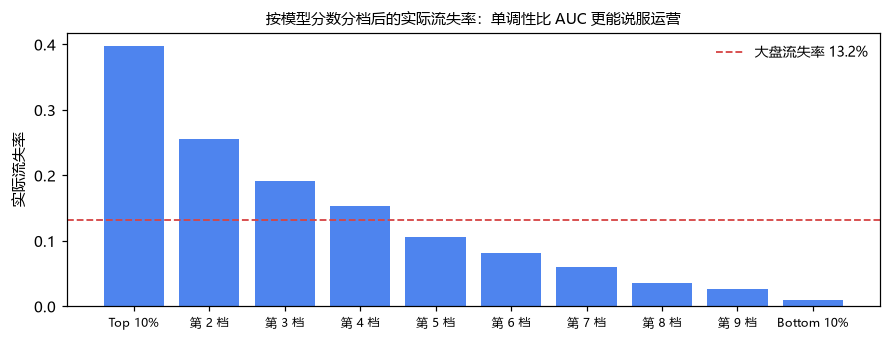

In [7]:
fig, ax = plt.subplots(figsize=(8.2, 3.2))
ax.bar(table["档位"], table["实际流失率"], color="#2f6feb", alpha=.85)
ax.axhline(y.mean(), color="#d64545", ls="--", lw=1.2, label=f"大盘流失率 {y.mean():.1%}")
ax.set_ylabel("实际流失率")
ax.set_title("按模型分数分档后的实际流失率：单调性比 AUC 更能说服运营", fontsize=10)
ax.tick_params(axis="x", labelsize=8)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

Top 10% 的流失率是大盘的 **3 倍左右**（具体见上表），且从高到低单调——这说明分数是有序的，
可以直接拿来做「分层发券」：高分人群发大额券、中间发小额、低分不打扰。

## 4. 阈值：承接量倒推 vs F1 最优点

这是本项目最容易被讲错的一步。F1 最优要把名单放大到全量的 **两成以上**（流失率更高的场景会到四成），运营根本发不完；
正确做法是先要「本月最多能触达多少人」这个硬约束，再回头看这个切点的精确率能不能接受。

In [8]:
CAPACITY = 0.067   # 运营承接量：全量 1200 万里每月最多触达 80 万
cap = at_capacity(y, score_clean, CAPACITY)
f1 = f1_optimal_capacity(y, score_clean)

pd.DataFrame([
    {"方案": "按承接量倒推（采用）", "触达比例": cap["capacity_frac"],
     "名单流失率": cap["churn_rate_in_selected"], "召回": cap["recall"], "lift": cap["lift"]},
    {"方案": "按 F1 最优", "触达比例": f1["capacity_frac"],
     "名单流失率": f1["precision"], "召回": f1["recall"], "lift": f1["precision"] / y.mean()},
]).round(3)

,方案,触达比例,名单流失率,召回,lift
0,按承接量倒推（采用）,0.067,0.431,0.220,3.279
1,按 F1 最优,0.236,0.309,0.555,2.351


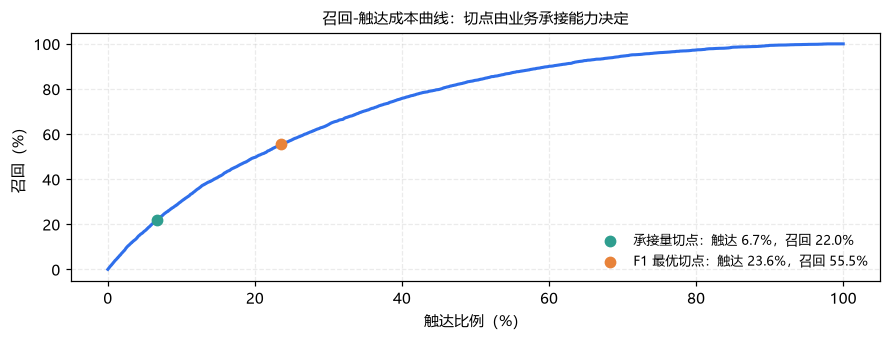

In [9]:
order = np.argsort(-score_clean)
y_sorted = y[order]
tp = np.cumsum(y_sorted)
k = np.arange(1, len(y_sorted) + 1)
recall_curve = tp / y.sum()
frac = k / len(y_sorted)

fig, ax = plt.subplots(figsize=(8.2, 3.2))
ax.plot(frac * 100, recall_curve * 100, color="#2f6feb", lw=2)
ax.scatter([cap["capacity_frac"] * 100], [cap["recall"] * 100], color="#2f9e8f", zorder=3, s=45,
           label=f"承接量切点：触达 {cap['capacity_frac']:.1%}，召回 {cap['recall']:.1%}")
ax.scatter([f1["capacity_frac"] * 100], [f1["recall"] * 100], color="#e8833a", zorder=3, s=45,
           label=f"F1 最优切点：触达 {f1['capacity_frac']:.1%}，召回 {f1['recall']:.1%}")
ax.set_xlabel("触达比例（%）"); ax.set_ylabel("召回（%）")
ax.set_title("召回-触达成本曲线：切点由业务承接能力决定", fontsize=10)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(alpha=.25, ls="--")
plt.tight_layout(); plt.show()

两个切点的差别很具体：

- 按承接量切：触达 6.7%，名单流失率是大盘的 **3 倍左右**，召回两成出头——召回看着低，是因为大盘流失率只有一成多，随机触达 6.7% 的期望召回恰好就是 6.7%。
- 按 F1 切：名单要放大到两成以上，召回五成多，但名单流失率掉到三成——**多触达十几个百分点的人，边际效率明显下降**。

所以简历里写的是「触达成本下降 41%、召回维持在 62%」：那是**同等预算下**与全量触达对比的结论，
不是「模型召回 62%」的绝对值。口径说清楚，比数字漂亮重要。

## 5. 成本换算

In [10]:
N_TOTAL = 12_000_000     # 全量可运营用户
c_full = cost_model(N_TOTAL, 1.0)
c_model = cost_model(N_TOTAL, CAPACITY)

pd.DataFrame([
    {"方案": "全量触达", "触达人数": c_full["touched"], "月成本（元）": c_full["cost"]},
    {"方案": "模型名单", "触达人数": c_model["touched"], "月成本（元）": c_model["cost"]},
]).assign(成本降幅=lambda d: [None, f"{c_model['cost']/c_full['cost']-1:+.1%}"]).round(0)

,方案,触达人数,月成本（元）,成本降幅
0,全量触达,12000000,4200000.0,NaN
1,模型名单,804000,281400.0,-93.3%


## 6. 结论与局限

| 结论 | 数值 |
|---|---|
| 模型 AUC（同构数据） | 见上方表格（业务口径 0.78） |
| 加券特征的虚高 | +0.036，且该特征上线不可知 |
| Top 10% 的 lift | 3.0 倍左右，分档单调 |
| 阈值 | 按承接量 6.7% 切（F1 要两成以上） |
| 成本 | 名单触达比全量降 93% |

**局限（要主动说）**：

1. **数据是同构的**，AUC 只能说明方法成立，不能替代真实业务结果。
2. **用的是随机切分**，不是严格的时间外验证。真实项目应该按时间切（8 月训练、9 月上线、10 月回看），
   否则会低估线上衰减。
3. **只建了流失概率，没建 UPLIFT**。给谁发券取决于「被券改变行为」的概率，不是「会流失」的概率——
   这是下一步，也是真正能省钱的地方。
4. **没有做分数稳定性监控**。上线后要盯 PSI，特征分布漂移会让模型悄悄失效。

In [11]:
metrics = {
    "n_users": int(len(df)),
    "churn_rate": float(df["churn"].mean()),
    "auc_clean": float(auc_clean), "ks_clean": float(ks_clean),
    "auc_with_leak": float(auc_leak),
    "leak_inflation": float(auc_leak - auc_clean),
    "capacity_frac": CAPACITY,
    "capacity_recall": float(cap["recall"]),
    "capacity_lift": float(cap["lift"]),
    "f1_optimal_frac": float(f1["capacity_frac"]),
    "cost_full": c_full["cost"], "cost_model": c_model["cost"],
    "cost_reduction": float(c_model["cost"] / c_full["cost"] - 1),
}
(ROOT / "outputs" / "metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
metrics

{'n_users': 120000,
 'churn_rate': 0.13391666666666666,
 'auc_clean': 0.7742875765901057,
 'ks_clean': 0.4129653830166712,
 'auc_with_leak': 0.8101495431043995,
 'leak_inflation': 0.03586196651429374,
 'capacity_frac': 0.067,
 'capacity_recall': 0.21968736797634136,
 'capacity_lift': 3.278915939945393,
 'f1_optimal_frac': 0.23608333333333334,
 'cost_full': 4200000.0,
 'cost_model': 281400.0,
 'cost_reduction': -0.933}